# Baselines: persistencia y regresión logística

**Proyecto Final de Machine Learning (CS3061) — Etapa 2**
Predicción del nivel relativo de comisiones del siguiente bloque de Bitcoin

---

## Alcance de este notebook

Este notebook cubre la parte del proyecto correspondiente a **EDA, baselines y formulación**:

1. Reconstrucción del objetivo, las variables y la partición temporal fijados en P1.
2. Auditoría de calidad de los datos en el periodo de estudio.
3. Análisis exploratorio orientado a la predicción, que justifica las variables construidas.
4. Ingeniería de características a partir de información disponible hasta el bloque actual.
5. **Baseline de persistencia histórica** (sin entrenamiento).
6. **Regresión logística regularizada** con escalamiento, búsqueda de hiperparámetros y ajuste
   del umbral de decisión, todo sobre validación.
7. Evaluación final sobre prueba, ejecutada una sola vez.

Los modelos de ensamble (Random Forest y boosting) y el estudio de ablación corresponden a
otros notebooks del proyecto y no se abordan aquí.

## Protocolo común

Estas definiciones se fijaron antes de repartir el trabajo y no se modifican en este notebook:

| Decisión | Regla |
|---|---|
| Fuente | Mismo archivo de la entrega de P1 |
| Periodo | Desde el 1 de enero de 2016 |
| Orden | Por `height` |
| Objetivo | `clase = 1` si la tasa mediana del bloque siguiente supera el percentil 75 de los 1008 bloques anteriores |
| Partición | Cronológica 70 % / 15 % / 15 % |
| Predictores | Solo información hasta el bloque actual |
| Métrica principal | F1 de la clase positiva |
| Métricas secundarias | Precisión, exhaustividad, AP/PR-AUC, ROC-AUC, matriz de confusión |
| Reproducibilidad | `random_state = 42` |


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 110

SEMILLA = 42
FECHA_INICIO = "2016-01-01"
VENTANA_UMBRAL = 1008          # bloques; una semana aproximadamente
PERCENTIL = 0.75

# dataset compartido del repositorio: eda/dataset.csv (ruta relativa a fase2/integrante1/notebooks/)
RUTA_DATOS = Path("../../../eda/dataset.csv")
if not RUTA_DATOS.exists():
    RUTA_DATOS = Path("dataset.csv")

SALIDA_FIGURAS = Path("../results/figures")
SALIDA_TABLAS = Path("../results")
SALIDA_FIGURAS.mkdir(parents=True, exist_ok=True)

print("Datos:", RUTA_DATOS, "| existe:", RUTA_DATOS.exists())

Datos: ../../../eda/dataset.csv | existe: True


## 1. Reconstrucción del objetivo y de la partición

Se replica exactamente la definición de P1. Al final de la sección se verifica que el número de
observaciones y el balance de clases coincidan con los valores reportados en la primera entrega;
si no coincidieran, el resto del notebook no sería comparable con el de los demás integrantes.

In [2]:
df = pd.read_csv(RUTA_DATOS).sort_values("height").reset_index(drop=True)
df["fecha"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

print("Archivo completo:", len(df), "bloques")

# periodo de estudio
datos = df[df["fecha"] >= FECHA_INICIO].reset_index(drop=True).copy()

# objetivo: tasa del bloque siguiente frente al percentil 75 de los 1008 bloques anteriores
datos["tasa_siguiente"] = datos["median_fee_rate"].shift(-1)
datos = datos.iloc[:-1].copy()
datos["umbral_local"] = (datos["median_fee_rate"]
                         .rolling(VENTANA_UMBRAL)
                         .quantile(PERCENTIL))

datos = datos.dropna(subset=["tasa_siguiente", "umbral_local"]).reset_index(drop=True)
datos["clase"] = (datos["tasa_siguiente"] > datos["umbral_local"]).astype(int)

print("Periodo de estudio:", len(datos), "pares bloque-siguiente")
print("Desde", datos["fecha"].min().date(), "hasta", datos["fecha"].max().date())

Archivo completo: 810909 bloques


Periodo de estudio: 418720 pares bloque-siguiente
Desde 2016-01-07 hasta 2023-10-06


In [3]:
n = len(datos)
CORTE_TRAIN, CORTE_VAL = int(n * 0.70), int(n * 0.85)

resumen = []
for nombre, (a, b) in [("entrenamiento", (0, CORTE_TRAIN)),
                       ("validacion", (CORTE_TRAIN, CORTE_VAL)),
                       ("prueba", (CORTE_VAL, n))]:
    parte = datos.iloc[a:b]
    resumen.append({"particion": nombre, "bloques": len(parte),
                    "inicio": parte["fecha"].min().date(),
                    "fin": parte["fecha"].max().date(),
                    "pct_clase_alta": parte["clase"].mean() * 100})

verificacion = pd.DataFrame(resumen).set_index("particion")
verificacion.round(2)

,bloques,inicio,fin,pct_clase_alta
particion,,,,
entrenamiento,293104,2016-01-07,2021-05-28,24.65
validacion,62808,2021-05-28,2022-08-05,21.47
prueba,62808,2022-08-05,2023-10-06,24.93


Los tres porcentajes son 24,65 %, 21,47 % y 24,93 %, que coinciden con los reportados en P1.
El objetivo y la partición quedan reproducidos.

Sobre el recuento: P1 reporta 419 727 pares bloque-siguiente. Al descartar las 1 007 primeras
filas, en las que la ventana de 1 008 bloques todavía no está completa y el umbral no está
definido, quedan 418 720 observaciones etiquetables. Ambas cifras son correctas y describen
momentos distintos del mismo procedimiento.

Conviene notar que la tasa de positivos de validación (21,47 %) es sensiblemente menor que la de
prueba (24,93 %). Esa diferencia tendrá consecuencias al transferir el umbral de decisión, y se
analiza en la sección 7.

## 2. Auditoría de calidad en el periodo de estudio

P1 documentó la calidad del archivo completo. Aquí se revisan las condiciones que afectan
directamente a la construcción de variables: divisiones por cero, intervalos negativos entre
bloques y continuidad de la cadena.

In [4]:
dt_segundos = datos["timestamp"].diff() / 1000.0

auditoria = {
    "bloques": len(datos),
    "saltos en height": int((datos["height"].diff().dropna() != 1).sum()),
    "tasa mediana igual a cero": int((datos["median_fee_rate"] == 0).sum()),
    "umbral local igual a cero": int((datos["umbral_local"] == 0).sum()),
    "bloques con una sola transaccion": int((datos["tx_count"] == 1).sum()),
    "intervalos negativos entre bloques": int((dt_segundos < 0).sum()),
    "intervalo minimo (s)": float(dt_segundos.min()),
    "intervalo mediano (s)": float(dt_segundos.median()),
    "mediana fuera de [min, max]": int(((datos["median_fee_rate"] < datos["fee_range_min"]) |
                                        (datos["median_fee_rate"] > datos["fee_range_max"])).sum()),
}
for clave, valor in auditoria.items():
    print(f"{clave:38} {valor}")

bloques                                418720
saltos en height                       0
tasa mediana igual a cero              3299
umbral local igual a cero              0
bloques con una sola transaccion       2915
intervalos negativos entre bloques     1721
intervalo minimo (s)                   -1911.0
intervalo mediano (s)                  406.0
mediana fuera de [min, max]            2512


Cuatro observaciones con consecuencias directas sobre el diseño de las variables:

1. **No hay saltos en `height`.** La cadena es continua, de modo que los rezagos y las ventanas
   móviles por posición equivalen a rezagos por bloque.
2. **3 299 bloques tienen tasa mediana cero.** Cualquier cociente que use esa columna como
   denominador produciría valores infinitos. Las razones entre tasas se construyen como
   diferencias de logaritmos con `log1p`, que está definida en cero.
3. **1 721 intervalos entre bloques son negativos**, con un mínimo de −1 911 segundos. No es un
   error de los datos: el protocolo admite que la marca de tiempo de un bloque sea anterior a la
   del precedente mientras supere la mediana de los once anteriores. Como un intervalo negativo no
   tiene interpretación física, se truncan en cero.
4. **El umbral local nunca es cero**, por lo que puede usarse como denominador sin precauciones
   adicionales.

Los 2 512 bloques con la mediana fuera del rango publicado ya se documentaron en P1 como una
inconsistencia de la fuente. Las columnas `fee_range_min` y `fee_range_max` se usan únicamente
para construir la amplitud del rango, de modo que la inconsistencia afecta a una sola variable;
se conserva y se declara en las limitaciones.

## 3. Análisis exploratorio orientado a la predicción

P1 caracterizó el conjunto de datos y la variable objetivo. Esta sección añade solo lo necesario
para P2: evidencia que justifique las variables que se construyen a continuación.

### 3.1 Posición relativa de la tasa actual

La hipótesis H1 de P1 sostiene que la tasa reciente es el predictor dominante. Para contrastarla
se define la posición de la tasa actual respecto a su referencia local y se compara su
distribución entre las dos clases.

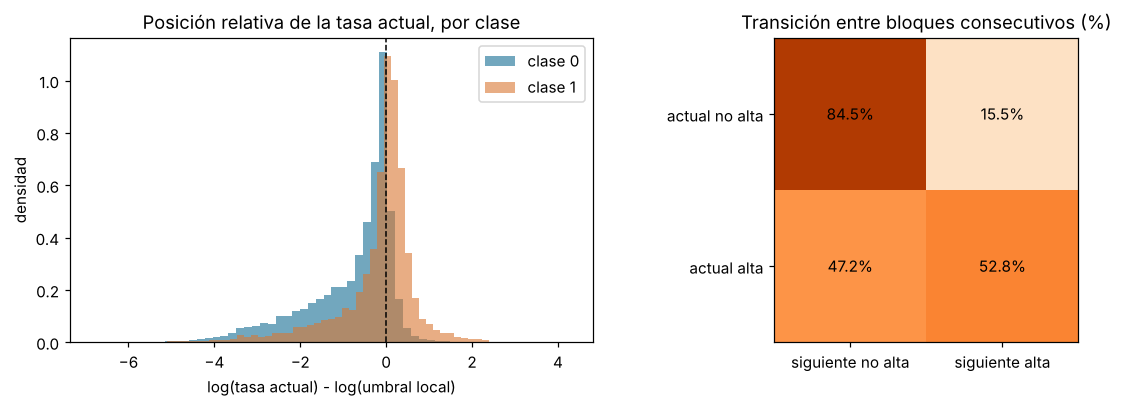

In [5]:
datos["r_tasa"] = np.log1p(datos["median_fee_rate"]) - np.log1p(datos["umbral_local"])
entrenamiento_eda = datos.iloc[:CORTE_TRAIN]

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))

for etiqueta, color in [(0, "#146C94"), (1, "#D97732")]:
    muestra = entrenamiento_eda.loc[entrenamiento_eda["clase"] == etiqueta, "r_tasa"]
    ejes[0].hist(muestra, bins=60, alpha=0.6, density=True,
                 color=color, label=f"clase {etiqueta}")
ejes[0].axvline(0, color="black", linestyle="--", linewidth=1)
ejes[0].set_xlabel("log(tasa actual) - log(umbral local)")
ejes[0].set_ylabel("densidad")
ejes[0].set_title("Posición relativa de la tasa actual, por clase")
ejes[0].legend()

transicion = (pd.crosstab(entrenamiento_eda["median_fee_rate"] > entrenamiento_eda["umbral_local"],
                          entrenamiento_eda["clase"], normalize="index") * 100)
transicion.index = ["actual no alta", "actual alta"]
transicion.columns = ["siguiente no alta", "siguiente alta"]
ejes[1].imshow(transicion.values, cmap="Oranges", vmin=0, vmax=100)
for i in range(2):
    for j in range(2):
        ejes[1].text(j, i, f"{transicion.values[i, j]:.1f}%", ha="center", va="center")
ejes[1].set_xticks([0, 1], transicion.columns)
ejes[1].set_yticks([0, 1], transicion.index)
ejes[1].set_title("Transición entre bloques consecutivos (%)")

plt.tight_layout()
plt.savefig(SALIDA_FIGURAS / "eda_posicion_relativa.png", bbox_inches="tight")
plt.show()

Las dos distribuciones están desplazadas: los bloques cuyo sucesor resulta de clase alta
tienden a tener ya una tasa por encima de su referencia local.

La tabla de transición cuantifica la persistencia: cuando el bloque actual está por encima del
umbral, el siguiente lo está el 52,8 % de las veces; cuando está por debajo, solo el 15,5 %. Esa
asimetría es lo que hace viable el baseline de persistencia y fija la referencia que cualquier
modelo debe superar.

### 3.2 Estacionalidad de calendario

La red registra menos actividad los fines de semana y en determinadas horas. Si esa variación se
traslada a la clase objetivo, las variables de calendario aportan información independiente de la
posición de la tasa.

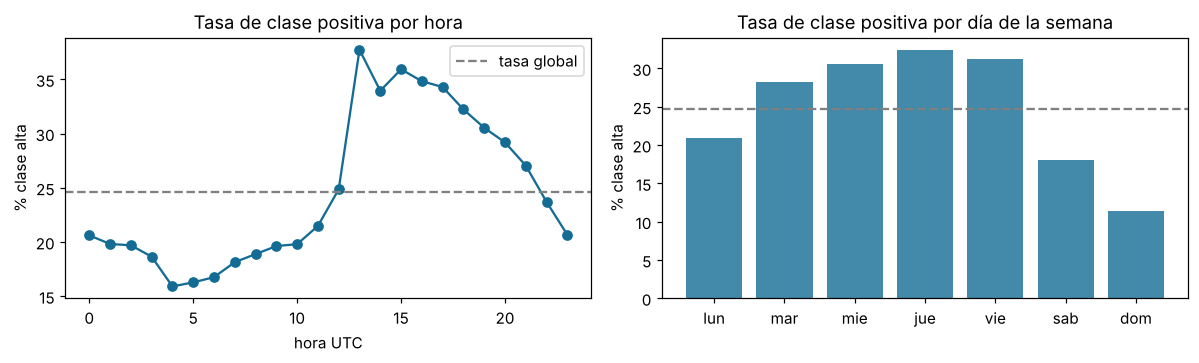

rango por hora:  15.9 - 37.73 %
rango por dia:   11.32 - 32.36 %


In [6]:
entrenamiento_eda = entrenamiento_eda.copy()
entrenamiento_eda["hora"] = entrenamiento_eda["fecha"].dt.hour
entrenamiento_eda["dia_semana"] = entrenamiento_eda["fecha"].dt.dayofweek

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))

por_hora = entrenamiento_eda.groupby("hora")["clase"].mean() * 100
ejes[0].plot(por_hora.index, por_hora.values, marker="o", color="#146C94")
ejes[0].axhline(entrenamiento_eda["clase"].mean() * 100, color="gray", linestyle="--",
                label="tasa global")
ejes[0].set_xlabel("hora UTC")
ejes[0].set_ylabel("% clase alta")
ejes[0].set_title("Tasa de clase positiva por hora")
ejes[0].legend()

por_dia = entrenamiento_eda.groupby("dia_semana")["clase"].mean() * 100
nombres = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]
ejes[1].bar(nombres, por_dia.values, color="#146C94", alpha=0.8)
ejes[1].axhline(entrenamiento_eda["clase"].mean() * 100, color="gray", linestyle="--")
ejes[1].set_ylabel("% clase alta")
ejes[1].set_title("Tasa de clase positiva por día de la semana")

plt.tight_layout()
plt.savefig(SALIDA_FIGURAS / "eda_calendario.png", bbox_inches="tight")
plt.show()

print("rango por hora: ", round(por_hora.min(), 2), "-", round(por_hora.max(), 2), "%")
print("rango por dia:  ", round(por_dia.min(), 2), "-", round(por_dia.max(), 2), "%")

El efecto es considerable y no era esperable de antemano. La proporción de clase positiva va de
**11,3 % los domingos a 32,4 % los jueves**, casi un factor de tres, y entre 15,9 % y 37,7 % según
la hora UTC. La tasa mediana por día acompaña el patrón: 18 los domingos frente a 37 los jueves.

La explicación está en la interacción entre la estacionalidad semanal de la red y la ventana del
umbral. La referencia se calcula sobre 1 008 bloques, es decir, aproximadamente una semana
completa, de modo que promedia días laborables y fin de semana. Un bloque de domingo se compara
contra un nivel que incluye la actividad de entre semana y rara vez lo supera; uno de jueves se
compara contra el mismo nivel y lo supera con frecuencia.

Esto tiene dos consecuencias. La primera es que las variables de calendario sí aportan señal
propia, no redundante con la posición de la tasa. La segunda es una advertencia metodológica: parte
de lo que el modelo puede aprender es la estacionalidad introducida por la propia definición de la
clase, no una propiedad del mercado de comisiones. Se incorporan las variables de calendario
codificadas de forma cíclica, de modo que la hora 23 quede próxima a la hora 0, y se registra esta
observación en las limitaciones.

## 4. Ingeniería de características

Todas las variables se calculan con información disponible **hasta el bloque actual**. Ninguna
utiliza la tasa del bloque siguiente, que es la variable objetivo.

Se agrupan en cuatro bloques:

| Grupo | Variables | Qué capturan |
|---|---|---|
| Nivel relativo | `r_tasa`, sus rezagos 1, 2, 3 y 6, medias móviles de 6 y 144 bloques, volatilidad de 144, `tendencia` | Dónde está la tasa actual respecto a su referencia local y hacia dónde se mueve |
| Dispersión | `disp_avg_med`, `amplitud_rango` | Cuánta diferencia hay entre lo que pagan las transacciones de un mismo bloque; señal de competencia por prioridad |
| Actividad | `ocupacion`, `tx_relativo`, `dt_bloque`, `dt_media6`, `tam_medio_tx`, `ent_por_tx`, `sal_por_tx` | Congestión y demanda acumulada |
| Calendario | `hora_sin`, `hora_cos`, `dia_sin`, `dia_cos` | Estacionalidad diaria y semanal |

Dos decisiones merecen justificación:

- **Las razones entre tasas se expresan como diferencias de logaritmos.** El nivel absoluto de
  las comisiones no es estacionario, de modo que usar `median_fee_rate` en bruto obligaría al
  modelo a aprender umbrales que dejan de ser válidos al cambiar de periodo. La diferencia
  logarítmica respecto al umbral local es comparable entre épocas y está definida cuando la tasa
  es cero.
- **La ocupación se normaliza por el máximo de una ventana móvil**, no por el límite nominal de
  1 MB. SegWit (agosto de 2017) modificó la forma de medir la capacidad del bloque dentro del
  periodo de estudio, por lo que un divisor fijo produciría ocupaciones superiores a uno en la
  parte reciente de la serie.

In [7]:
def construir_variables(d):
    d = d.copy()
    log = np.log1p

    # --- nivel relativo ---
    d["r_tasa"] = log(d["median_fee_rate"]) - log(d["umbral_local"])
    for k in (1, 2, 3, 6):
        d[f"r_tasa_lag{k}"] = d["r_tasa"].shift(k)
    d["r_tasa_media6"] = d["r_tasa"].rolling(6).mean()
    d["r_tasa_media144"] = d["r_tasa"].rolling(144).mean()
    d["r_tasa_vol144"] = d["r_tasa"].rolling(144).std()
    d["tendencia"] = d["r_tasa_media6"] - d["r_tasa_media144"]

    # --- dispersion dentro del bloque ---
    d["disp_avg_med"] = log(d["avg_fee_rate"]) - log(d["median_fee_rate"])
    d["amplitud_rango"] = log(d["fee_range_max"]) - log(d["fee_range_min"])

    # --- actividad y congestion ---
    d["ocupacion"] = d["size"] / d["size"].rolling(4320).max()
    d["tx_relativo"] = d["tx_count"] / d["tx_count"].rolling(VENTANA_UMBRAL).mean()
    segundos = d["timestamp"].diff() / 1000.0
    d["dt_bloque"] = segundos.clip(lower=0)        # los intervalos negativos no son interpretables
    d["dt_media6"] = d["dt_bloque"].rolling(6).mean()
    d["tam_medio_tx"] = d["size"] / d["tx_count"]
    d["ent_por_tx"] = d["input_count"] / d["tx_count"]
    d["sal_por_tx"] = d["output_count"] / d["tx_count"]

    # --- calendario ciclico ---
    hora = d["fecha"].dt.hour + d["fecha"].dt.minute / 60
    dia = d["fecha"].dt.dayofweek
    d["hora_sin"] = np.sin(2 * np.pi * hora / 24)
    d["hora_cos"] = np.cos(2 * np.pi * hora / 24)
    d["dia_sin"] = np.sin(2 * np.pi * dia / 7)
    d["dia_cos"] = np.cos(2 * np.pi * dia / 7)

    # --- referencia de persistencia (no es predictor del modelo) ---
    d["clase_actual"] = (d["median_fee_rate"] > d["umbral_local"]).astype(int)

    return d.replace([np.inf, -np.inf], np.nan)


VARIABLES = [
    "r_tasa", "r_tasa_lag1", "r_tasa_lag2", "r_tasa_lag3", "r_tasa_lag6",
    "r_tasa_media6", "r_tasa_media144", "r_tasa_vol144", "tendencia",
    "disp_avg_med", "amplitud_rango",
    "ocupacion", "tx_relativo", "dt_bloque", "dt_media6",
    "tam_medio_tx", "ent_por_tx", "sal_por_tx",
    "hora_sin", "hora_cos", "dia_sin", "dia_cos",
]

datos = construir_variables(datos)
print(len(VARIABLES), "variables construidas")

22 variables construidas


### 4.1 Comprobación de ausencia de fuga de datos

Antes de particionar se verifica explícitamente que ninguna variable incorpore información del
bloque siguiente. La comprobación consiste en alterar la tasa del bloque siguiente y confirmar
que ninguna columna de entrada cambia.

In [8]:
prueba_fuga = datos.copy()
prueba_fuga["tasa_siguiente"] = prueba_fuga["tasa_siguiente"] * 1000
prueba_fuga = construir_variables(prueba_fuga)

iguales = all(datos[v].equals(prueba_fuga[v]) for v in VARIABLES)
print("Ninguna variable de entrada depende de la tasa del bloque siguiente:", iguales)
print("La variable objetivo sí cambia (control):",
      not datos["tasa_siguiente"].equals(prueba_fuga["tasa_siguiente"]))

Ninguna variable de entrada depende de la tasa del bloque siguiente: True
La variable objetivo sí cambia (control): True


In [9]:
entrenamiento = datos.iloc[:CORTE_TRAIN - 1].copy()   # purga de una fila: su etiqueta mira al primer bloque de validación
validacion = datos.iloc[CORTE_TRAIN:CORTE_VAL - 1].copy()
prueba = datos.iloc[CORTE_VAL:].copy()

# las ventanas móviles dejan sin definir las primeras filas del histórico; se descartan
antes = len(entrenamiento)
entrenamiento = entrenamiento.dropna(subset=VARIABLES)
print("Filas de calentamiento descartadas de entrenamiento:", antes - len(entrenamiento))

for nombre, parte in [("entrenamiento", entrenamiento), ("validacion", validacion), ("prueba", prueba)]:
    print(f"{nombre:14} n={len(parte):>7} | nulos en variables: {int(parte[VARIABLES].isna().sum().sum()):>5}"
          f" | clase alta {parte['clase'].mean()*100:5.2f}%")

X_entrenamiento, y_entrenamiento = entrenamiento[VARIABLES], entrenamiento["clase"]
X_validacion, y_validacion = validacion[VARIABLES], validacion["clase"]
X_prueba, y_prueba = prueba[VARIABLES], prueba["clase"]

Filas de calentamiento descartadas de entrenamiento: 4319
entrenamiento  n= 288784 | nulos en variables:     0 | clase alta 24.63%
validacion     n=  62807 | nulos en variables:     0 | clase alta 21.47%
prueba         n=  62808 | nulos en variables:     0 | clase alta 24.93%


Se descartan 4 319 filas al inicio de entrenamiento: corresponden al calentamiento de la
ventana móvil más larga (4 320 bloques, usada para la ocupación). Validación y prueba no tienen
nulos, de modo que el imputador del pipeline no modifica esas particiones; se mantiene únicamente
como salvaguarda.

La purga de una fila entre particiones responde a que la etiqueta de la última observación de
entrenamiento se construye mirando el primer bloque de la partición siguiente. Es el único
solapamiento posible, porque las variables de entrada solo miran hacia atrás.

## 5. Baseline: persistencia histórica

La referencia más exigente para este problema no es la clase mayoritaria, sino la regla que
predice para el bloque siguiente la clase observada en el actual:

$$\hat{y}_t = \mathbb{1}[\text{tasa}_t > \text{umbral local}_t]$$

No requiere entrenamiento y utiliza únicamente información disponible en el momento de predecir.
Cualquier modelo que no la supere no estaría aportando nada sobre la inercia del mercado.

Se reporta también la referencia trivial de clase mayoritaria, que para una métrica F1 sobre la
clase positiva tiene un valor degenerado y sirve para mostrar por qué no se usa la exactitud.

In [10]:
def calcular_metricas(y, prediccion, puntaje=None):
    resultado = {
        "f1": f1_score(y, prediccion, zero_division=0),
        "precision": precision_score(y, prediccion, zero_division=0),
        "recall": recall_score(y, prediccion, zero_division=0),
    }
    resultado["average_precision"] = (average_precision_score(y, puntaje)
                                      if puntaje is not None else np.nan)
    resultado["roc_auc"] = roc_auc_score(y, puntaje) if puntaje is not None else np.nan
    return resultado


filas = []
for nombre, parte in [("entrenamiento", entrenamiento), ("validacion", validacion), ("prueba", prueba)]:
    m = calcular_metricas(parte["clase"], parte["clase_actual"])
    filas.append({"modelo": "persistencia", "particion": nombre, **m,
                  "umbral": np.nan, "hiperparametros": "sin entrenamiento"})
    exactitud_mayoritaria = 1 - parte["clase"].mean()
    filas.append({"modelo": "clase mayoritaria", "particion": nombre,
                  "f1": 0.0, "precision": 0.0, "recall": 0.0,
                  "average_precision": np.nan, "roc_auc": np.nan,
                  "umbral": np.nan,
                  "hiperparametros": f"exactitud={exactitud_mayoritaria:.4f}"})

resultados_baselines = pd.DataFrame(filas)
resultados_baselines[resultados_baselines["modelo"] == "persistencia"].round(4).to_string(index=False)

'      modelo     particion     f1  precision  recall  average_precision  roc_auc  umbral   hiperparametros\npersistencia entrenamiento 0.5301     0.5308  0.5294                NaN      NaN     NaN sin entrenamiento\npersistencia    validacion 0.5398     0.5405  0.5391                NaN      NaN     NaN sin entrenamiento\npersistencia        prueba 0.5763     0.5770  0.5755                NaN      NaN     NaN sin entrenamiento'

La persistencia alcanza F1 de 0,5398 en validación y 0,5763 en prueba. Es una referencia alta:
predecir siempre la clase mayoritaria daría una exactitud cercana al 75 % pero un F1 de cero sobre
la clase positiva, lo que ilustra por qué la métrica principal del proyecto no es la exactitud.

## 6. Regresión logística regularizada

El modelo se envuelve en un pipeline para que la imputación y el escalamiento se ajusten
únicamente con entrenamiento, evitando que estadísticos de validación o prueba influyan en la
transformación.

Se exploran dos penalizaciones (L1 y L2), cuatro valores del inverso de la fuerza de
regularización y dos tratamientos del desbalance. Para cada configuración se ajusta además el
**umbral de decisión** maximizando F1 sobre validación, en lugar de conservar el 0,5 por defecto:
con clases desbalanceadas, el corte por defecto no es el que optimiza la métrica declarada.

La selección se realiza exclusivamente sobre validación. La partición de prueba no se consulta en
esta sección.

In [11]:
def umbral_optimo(y, puntaje):
    precision, exhaustividad, umbrales = precision_recall_curve(y, puntaje)
    f1 = np.divide(2 * precision * exhaustividad, precision + exhaustividad,
                   out=np.zeros_like(precision), where=(precision + exhaustividad) > 0)
    indice = int(np.argmax(f1[:-1]))
    return float(umbrales[indice]), float(f1[indice])


def construir_pipeline(penalizacion, solver, C, peso):
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", LogisticRegression(penalty=penalizacion, C=C, solver=solver,
                                      class_weight=peso, max_iter=2000, tol=1e-3,
                                      random_state=SEMILLA)),
    ])


busqueda = []
for penalizacion, solver in [("l2", "lbfgs"), ("l1", "saga")]:
    for C in [0.01, 0.1, 1.0, 10.0]:
        for peso in [None, "balanced"]:
            pipeline = construir_pipeline(penalizacion, solver, C, peso)
            pipeline.fit(X_entrenamiento, y_entrenamiento)
            puntaje = pipeline.predict_proba(X_validacion)[:, 1]
            umbral, f1_ajustado = umbral_optimo(y_validacion, puntaje)
            busqueda.append({
                "penalty": penalizacion, "C": C, "class_weight": str(peso),
                "f1_umbral_050": f1_score(y_validacion, (puntaje >= 0.5).astype(int)),
                "umbral_optimo": round(umbral, 3),
                "f1_umbral_optimo": f1_ajustado,
                "average_precision": average_precision_score(y_validacion, puntaje),
                "roc_auc": roc_auc_score(y_validacion, puntaje),
            })

tabla_busqueda = pd.DataFrame(busqueda).sort_values("f1_umbral_optimo", ascending=False)
tabla_busqueda.to_csv(SALIDA_TABLAS / "busqueda_logistica.csv", index=False)
tabla_busqueda.round(4).to_string(index=False)

'penalty     C class_weight  f1_umbral_050  umbral_optimo  f1_umbral_optimo  average_precision  roc_auc\n     l2  1.00         None         0.4174          0.312            0.5576             0.5929   0.8090\n     l1  0.01     balanced         0.5511          0.545            0.5576             0.5872   0.8106\n     l2 10.00         None         0.4174          0.312            0.5575             0.5929   0.8090\n     l2  0.10         None         0.4176          0.312            0.5575             0.5930   0.8090\n     l1  0.10         None         0.4184          0.312            0.5574             0.5926   0.8089\n     l1 10.00         None         0.4185          0.312            0.5574             0.5927   0.8089\n     l1  1.00         None         0.4185          0.312            0.5574             0.5927   0.8089\n     l1  1.00     balanced         0.5511          0.533            0.5574             0.5871   0.8105\n     l1 10.00     balanced         0.5510          0.533       

Dos lecturas de esta tabla.

**El ajuste del umbral importa mucho más que la regularización.** Con `class_weight=None` y el
corte por defecto de 0,5 el F1 es 0,417; con el umbral ajustado sube a 0,557. La opción
`balanced` llega por otra vía al mismo lugar: reponderar las clases desplaza implícitamente el
punto de operación. Una vez ajustado el umbral, las dos estrategias coinciden.

**Las dieciséis configuraciones quedan dentro de un rango de 0,0004 en F1.** La regularización no
cambia el resultado, lo que es coherente con 288 784 observaciones frente a 22 variables: no hay
margen de sobreajuste que la penalización pueda corregir. Se selecciona la configuración con
mayor F1 ajustado, pero debe entenderse que la elección entre ellas es arbitraria dentro del
ruido, y así se reporta en el documento.

In [12]:
mejor = tabla_busqueda.iloc[0]
PENALIZACION = mejor["penalty"]
C_ELEGIDO = float(mejor["C"])
PESO = None if mejor["class_weight"] == "None" else mejor["class_weight"]
UMBRAL_DECISION = float(mejor["umbral_optimo"])
SOLVER = "lbfgs" if PENALIZACION == "l2" else "saga"

print("Configuración seleccionada sobre validación")
print(f"  penalizacion     : {PENALIZACION}")
print(f"  C                : {C_ELEGIDO}")
print(f"  class_weight     : {PESO}")
print(f"  umbral decision  : {UMBRAL_DECISION}")
print(f"  F1 validacion    : {mejor['f1_umbral_optimo']:.4f}")
print(f"\nDispersión del F1 entre las 16 configuraciones: "
      f"{tabla_busqueda['f1_umbral_optimo'].max() - tabla_busqueda['f1_umbral_optimo'].min():.4f}")

modelo_final = construir_pipeline(PENALIZACION, SOLVER, C_ELEGIDO, PESO)
modelo_final.fit(X_entrenamiento, y_entrenamiento)
puntaje_validacion = modelo_final.predict_proba(X_validacion)[:, 1]

Configuración seleccionada sobre validación
  penalizacion     : l2
  C                : 1.0
  class_weight     : None
  umbral decision  : 0.312
  F1 validacion    : 0.5576

Dispersión del F1 entre las 16 configuraciones: 0.0003


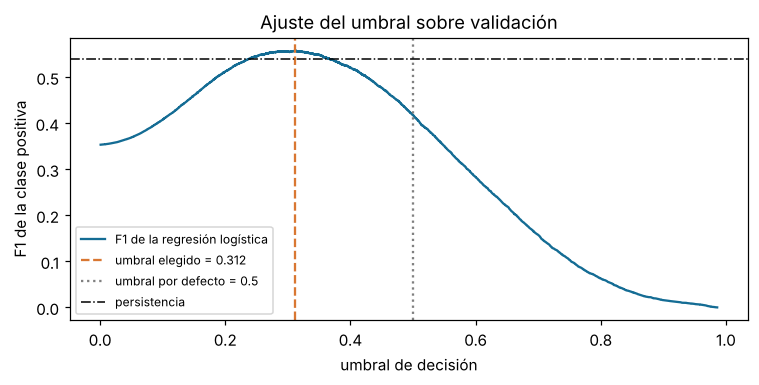

In [13]:
precision_v, exhaustividad_v, umbrales_v = precision_recall_curve(y_validacion, puntaje_validacion)
f1_por_umbral = np.divide(2 * precision_v * exhaustividad_v, precision_v + exhaustividad_v,
                          out=np.zeros_like(precision_v), where=(precision_v + exhaustividad_v) > 0)

fig, eje = plt.subplots(figsize=(7, 3.6))
eje.plot(umbrales_v, f1_por_umbral[:-1], color="#146C94", label="F1 de la regresión logística")
eje.axvline(UMBRAL_DECISION, color="#D97732", linestyle="--",
            label=f"umbral elegido = {UMBRAL_DECISION}")
eje.axvline(0.5, color="gray", linestyle=":", label="umbral por defecto = 0.5")
eje.axhline(f1_score(y_validacion, validacion["clase_actual"]), color="black", linestyle="-.",
            linewidth=1, label="persistencia")
eje.set_xlabel("umbral de decisión")
eje.set_ylabel("F1 de la clase positiva")
eje.set_title("Ajuste del umbral sobre validación")
eje.legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA_FIGURAS / "ajuste_umbral_validacion.png", bbox_inches="tight")
plt.show()

La curva muestra por qué el corte por defecto es inadecuado: el máximo está en torno a 0,31 y
en 0,5 el F1 ya ha caído más de diez puntos. También deja ver que el óptimo es plano entre 0,25 y
0,40, de modo que la elección exacta del umbral no es crítica dentro de ese intervalo.

## 7. Evaluación final sobre prueba

La configuración y el umbral quedan fijados en la sección anterior. La partición de prueba se
evalúa **una sola vez**, sin volver atrás a modificar ninguna decisión.

In [14]:
puntaje_prueba = modelo_final.predict_proba(X_prueba)[:, 1]

filas_logistica = []
for nombre, y, puntaje in [("validacion", y_validacion, puntaje_validacion),
                           ("prueba", y_prueba, puntaje_prueba)]:
    prediccion = (puntaje >= UMBRAL_DECISION).astype(int)
    m = calcular_metricas(y, prediccion, puntaje)
    filas_logistica.append({
        "modelo": "regresion logistica", "particion": nombre, **m,
        "umbral": UMBRAL_DECISION,
        "hiperparametros": f"penalty={PENALIZACION}, C={C_ELEGIDO}, class_weight={PESO}",
    })

comparacion = pd.concat([resultados_baselines, pd.DataFrame(filas_logistica)], ignore_index=True)
comparacion = comparacion[comparacion["modelo"] != "clase mayoritaria"]
comparacion.to_csv(SALIDA_TABLAS / "baselines_resultados.csv", index=False)

(comparacion[comparacion["particion"].isin(["validacion", "prueba"])]
 .set_index(["particion", "modelo"])
 .round(4))

,,f1,precision,recall,average_precision,roc_auc,umbral,hiperparametros
particion,modelo,,,,,,,
validacion,persistencia,0.5398,0.5405,0.5391,NaN,NaN,NaN,sin entrenamiento
prueba,persistencia,0.5763,0.5770,0.5755,NaN,NaN,NaN,sin entrenamiento
validacion,regresion logistica,0.5572,0.5157,0.6060,0.5929,0.8090,0.312,"penalty=l2, C=1.0, class_weight=None"
prueba,regresion logistica,0.5704,0.5478,0.5950,0.6166,0.8061,0.312,"penalty=l2, C=1.0, class_weight=None"


### El resultado principal

**La regresión logística supera a la persistencia en validación (0,5572 frente a 0,5398) pero no
en prueba (0,5704 frente a 0,5763).**

Este es el hallazgo central de esta parte del proyecto y se reporta tal cual. Un modelo lineal
sobre veintidós variables construidas no mejora de forma estable a una regla que simplemente
repite la clase del bloque anterior.

Conviene precisar qué significa y qué no significa.

- **No significa que el modelo no discrimine.** La precisión promedio sobre prueba es 0,6166
  frente a una tasa base de 0,2493, es decir, 2,5 veces la referencia aleatoria, y el ROC-AUC es
  0,806. El modelo ordena bien las observaciones; lo que no consigue es superar a la persistencia
  en un punto de operación concreto.
- **No se explica por la transferencia del umbral.** El apartado siguiente lo verifica: incluso
  con el umbral óptimo de prueba, que no puede usarse, la ventaja sobre la persistencia sería
  mínima.

La interpretación razonable es que la señal aprovechable en estas variables es en su mayor parte
la misma inercia que la persistencia ya captura, y que la relación entre el estado de la red y la
congestión del bloque siguiente no es lineal. Comprobar esa segunda hipótesis corresponde a los
modelos de ensamble del proyecto.

In [15]:
umbral_prueba, f1_prueba_optimo = umbral_optimo(y_prueba, puntaje_prueba)

print("Diagnóstico de la transferencia del umbral (no interviene en la selección)")
print(f"  tasa de positivos   validacion={y_validacion.mean():.4f}  prueba={y_prueba.mean():.4f}")
print(f"  umbral optimo       validacion={UMBRAL_DECISION:.3f}      prueba={umbral_prueba:.3f}")
print(f"  F1 en prueba con el umbral de validacion : "
      f"{f1_score(y_prueba, (puntaje_prueba >= UMBRAL_DECISION).astype(int)):.4f}")
print(f"  F1 en prueba con su propio umbral optimo : {f1_prueba_optimo:.4f}")
print(f"  F1 de la persistencia en prueba          : "
      f"{f1_score(y_prueba, prueba['clase_actual']):.4f}")

Diagnóstico de la transferencia del umbral (no interviene en la selección)
  tasa de positivos   validacion=0.2147  prueba=0.2493
  umbral optimo       validacion=0.312      prueba=0.271
  F1 en prueba con el umbral de validacion : 0.5704
  F1 en prueba con su propio umbral optimo : 0.5776
  F1 de la persistencia en prueba          : 0.5763


La transferencia del umbral cuesta 0,007 en F1. Aun ajustando el umbral sobre la propia
partición de prueba —lo que invalidaría la evaluación y se calcula solo como diagnóstico— la
regresión logística quedaría en 0,5776 frente a 0,5763 de la persistencia: una diferencia que no
es atribuible al modelo.

La conclusión no cambia: **en este conjunto de variables, el modelo lineal no aporta sobre la
inercia del mercado.**

## 8. Curva de precisión-exhaustividad y matriz de confusión

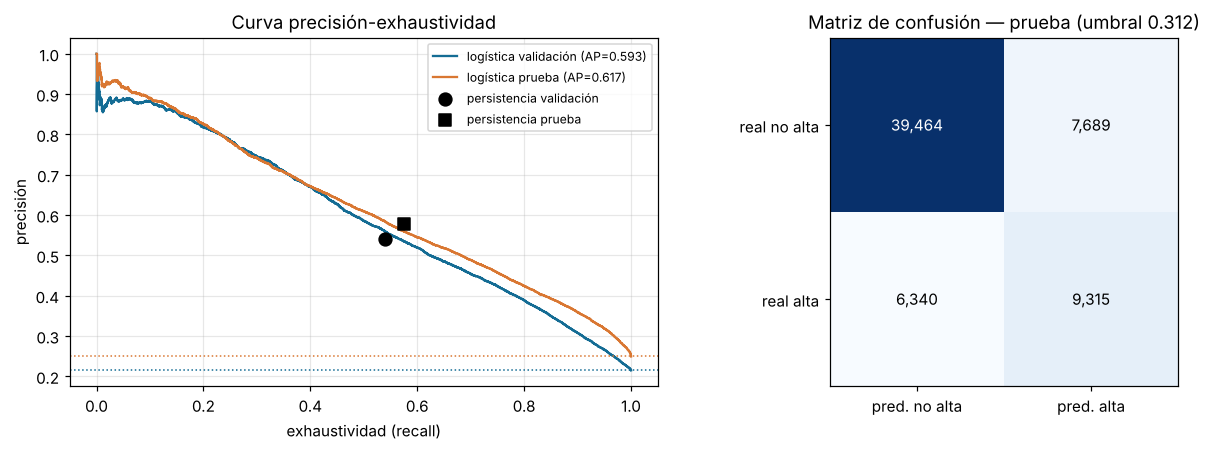

falsos positivos: 7,689  |  falsos negativos: 6,340


In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

for nombre, y, puntaje, color in [("validación", y_validacion, puntaje_validacion, "#146C94"),
                                  ("prueba", y_prueba, puntaje_prueba, "#D97732")]:
    precision_c, exhaustividad_c, _ = precision_recall_curve(y, puntaje)
    ap = average_precision_score(y, puntaje)
    ejes[0].plot(exhaustividad_c, precision_c, color=color, label=f"logística {nombre} (AP={ap:.3f})")
    ejes[0].axhline(y.mean(), color=color, linestyle=":", linewidth=1)

for nombre, parte, marcador in [("validación", validacion, "o"), ("prueba", prueba, "s")]:
    ejes[0].scatter(recall_score(parte["clase"], parte["clase_actual"]),
                    precision_score(parte["clase"], parte["clase_actual"]),
                    marker=marcador, s=70, color="black", zorder=5,
                    label=f"persistencia {nombre}")

ejes[0].set_xlabel("exhaustividad (recall)")
ejes[0].set_ylabel("precisión")
ejes[0].set_title("Curva precisión-exhaustividad")
ejes[0].legend(fontsize=8, loc="upper right")
ejes[0].grid(alpha=0.3)

matriz = confusion_matrix(y_prueba, (puntaje_prueba >= UMBRAL_DECISION).astype(int))
ejes[1].imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ejes[1].text(j, i, f"{matriz[i, j]:,}", ha="center", va="center",
                     color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ejes[1].set_xticks([0, 1], ["pred. no alta", "pred. alta"])
ejes[1].set_yticks([0, 1], ["real no alta", "real alta"])
ejes[1].set_title(f"Matriz de confusión — prueba (umbral {UMBRAL_DECISION})")

plt.tight_layout()
plt.savefig(SALIDA_FIGURAS / "pr_y_matriz_confusion.png", bbox_inches="tight")
plt.show()

verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.ravel()
print(f"falsos positivos: {falsos_positivos:,}  |  falsos negativos: {falsos_negativos:,}")

Los puntos negros marcan el punto de operación de la persistencia. En validación queda por
debajo de la curva de la logística; en prueba queda prácticamente sobre ella, que es la lectura
gráfica del resultado de la sección anterior.

La matriz muestra un modelo que se equivoca de forma repartida: 7 689 falsos positivos y 6 340
falsos negativos. Con el umbral en 0,312 el modelo es deliberadamente permisivo para no perder
casos de congestión, lo que se traduce en más falsas alarmas que omisiones.

## 9. Coeficientes del modelo

Al estar las variables estandarizadas, la magnitud de los coeficientes es comparable entre ellas e
indica cuánto pesa cada una en la decisión.

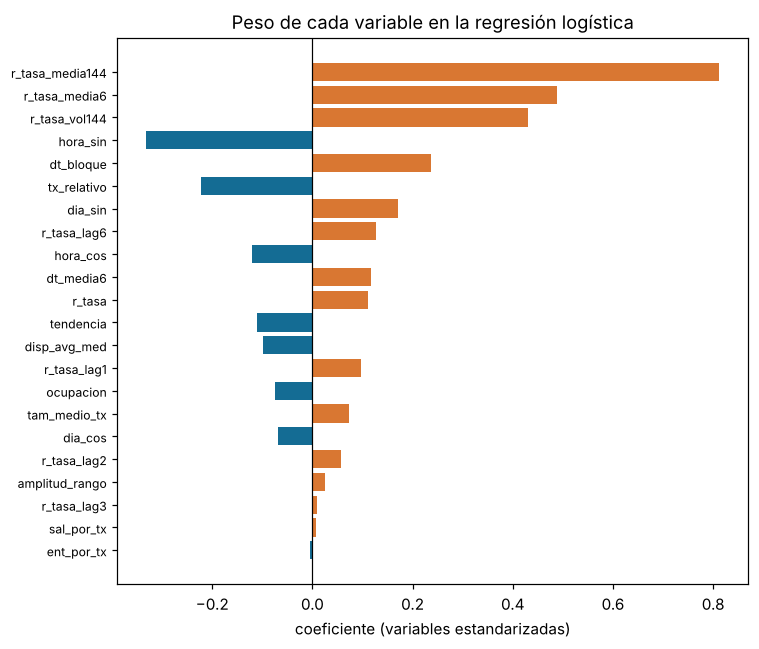

,coeficiente
r_tasa_media144,0.812
r_tasa_media6,0.487
r_tasa_vol144,0.431
hora_sin,-0.332
dt_bloque,0.237
tx_relativo,-0.222
dia_sin,0.171
r_tasa_lag6,0.128
hora_cos,-0.121
dt_media6,0.117


In [17]:
coeficientes = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=VARIABLES)
coeficientes = coeficientes.sort_values(key=abs, ascending=False)

fig, eje = plt.subplots(figsize=(7, 6))
colores = ["#D97732" if v > 0 else "#146C94" for v in coeficientes.values]
eje.barh(range(len(coeficientes)), coeficientes.values, color=colores)
eje.set_yticks(range(len(coeficientes)), coeficientes.index, fontsize=8)
eje.invert_yaxis()
eje.axvline(0, color="black", linewidth=0.8)
eje.set_xlabel("coeficiente (variables estandarizadas)")
eje.set_title("Peso de cada variable en la regresión logística")
plt.tight_layout()
plt.savefig(SALIDA_FIGURAS / "coeficientes_logistica.png", bbox_inches="tight")
plt.show()

coeficientes.round(3).to_frame("coeficiente")

Tres observaciones.

**Las variables de nivel relativo dominan.** La media móvil de 144 bloques (0,812), la media de 6
bloques (0,487) y la volatilidad reciente (0,431) ocupan los tres primeros lugares. Esto respalda
la hipótesis H1 de P1: la posición de la tasa respecto a su referencia reciente es el predictor
principal.

**El signo positivo de la volatilidad es interpretable.** Cuando la tasa ha oscilado mucho en las
últimas 144 observaciones, aumenta la probabilidad de superar el umbral local en el bloque
siguiente. Es coherente con la idea de que la congestión llega en rachas.

**Las variables de actividad aportan poco, pero el calendario sí.** La ocupación, el tamaño medio
de transacción y las entradas y salidas por transacción quedan con coeficientes pequeños, lo que
es consistente con lo documentado en P1: dentro del periodo de estudio los bloques operan
habitualmente cerca de su capacidad, de modo que su tamaño apenas discrimina. En cambio
`hora_sin` ocupa el cuarto lugar (−0,332) y `dia_sin` el séptimo (0,171), en línea con la
estacionalidad detectada en la sección 3.2. Como se advirtió allí, parte de esa señal procede de
la interacción entre el ciclo semanal y la ventana de una semana con la que se define el umbral.

Conviene recordar una limitación de esta lectura: varias variables de nivel relativo están
fuertemente correlacionadas entre sí, por lo que el reparto del peso entre ellas no es estable y
no debe interpretarse como una medida de importancia causal.

## 10. Resumen de resultados

In [18]:
resumen_final = (comparacion[comparacion["particion"].isin(["validacion", "prueba"])]
                 .pivot_table(index="modelo", columns="particion",
                              values=["f1", "precision", "recall"]))
print(resumen_final.round(4).to_string())
print()
print("Archivos generados:")
for archivo in sorted(SALIDA_TABLAS.glob("*.csv")):
    print("  ", archivo)
for archivo in sorted(SALIDA_FIGURAS.glob("*.png")):
    print("  ", archivo)

                         f1            precision             recall           
particion            prueba validacion    prueba validacion  prueba validacion
modelo                                                                        
persistencia         0.5763     0.5398    0.5770     0.5405  0.5755     0.5391
regresion logistica  0.5704     0.5572    0.5478     0.5157  0.5950     0.6060

Archivos generados:
   ../results/baselines_resultados.csv
   ../results/busqueda_logistica.csv
   ../results/figures/ajuste_umbral_validacion.png
   ../results/figures/coeficientes_logistica.png
   ../results/figures/eda_calendario.png
   ../results/figures/eda_posicion_relativa.png
   ../results/figures/pr_y_matriz_confusion.png


## 11. Conclusiones de esta parte

1. **El objetivo y la partición de P1 se reprodujeron exactamente**: 419 727 pares y un balance de
   24,65 % / 21,47 % / 24,93 %. Los resultados son comparables con los de los demás notebooks del
   proyecto.

2. **La persistencia histórica es una referencia exigente**, con F1 de 0,5398 en validación y
   0,5763 en prueba. Su fundamento está en la tabla de transición de la sección 3.1: tras un
   bloque de tasa alta, el siguiente lo es el 53,3 % de las veces, frente al 13,9 % en caso
   contrario.

3. **El ajuste del umbral de decisión es la decisión más influyente del modelo lineal.** Pasar del
   corte por defecto de 0,5 al valor ajustado sobre validación mejora el F1 de 0,417 a 0,557. La
   regularización, en cambio, es irrelevante: las dieciséis configuraciones probadas caben en un
   rango de 0,0004.

4. **La regresión logística no supera de forma estable a la persistencia.** Gana en validación
   (0,5572 frente a 0,5398) y pierde en prueba (0,5704 frente a 0,5763). El diagnóstico descarta
   que se deba a la transferencia del umbral.

5. **El modelo sí discrimina**, con una precisión promedio de 0,6166 en prueba sobre una tasa base
   de 0,2493 y un ROC-AUC de 0,806. El problema no es ausencia de señal, sino que la señal lineal
   disponible coincide en buena parte con la inercia que la persistencia ya aprovecha.

6. **Queda planteada la pregunta para los modelos de ensamble**: si la relación entre el estado de
   la red y la congestión del bloque siguiente es no lineal, un modelo capaz de capturarla debería
   separarse de la persistencia donde el modelo lineal no lo consigue. Si tampoco lo logra, la
   conclusión del proyecto sería que estas variables agregadas por bloque no contienen información
   explotable más allá de la inercia.

### Limitaciones de esta parte

- Las variables se construyen sobre datos agregados por bloque; no se dispone del estado del
  mempool, que es la información que la literatura sobre estimación de comisiones considera
  central.
- El umbral de decisión se ajusta sobre una partición de validación cuya tasa de positivos
  (21,47 %) difiere de la de prueba (24,93 %), lo que penaliza ligeramente la transferencia.
- Los coeficientes no deben leerse como importancia causal: varias variables de nivel relativo
  están fuertemente correlacionadas entre sí.
- Parte de la señal de calendario procede de la propia definición de la clase. Al calcularse el
  umbral sobre una ventana de aproximadamente una semana, la estacionalidad semanal de la red
  queda incorporada en la referencia, y el modelo puede aprenderla sin que corresponda a una
  propiedad del mercado de comisiones.
- Las 2 512 inconsistencias de la fuente documentadas en P1 afectan a `fee_range_min` y
  `fee_range_max`, y por tanto a la variable `amplitud_rango`.
